# Unidad 2 — Modelos bayesianos

**Módulo 6: Modelos Avanzados de IA y Aplicaciones Económicas — CEC EPN / Banco Central del Ecuador**  
**Fechas:** 13-11 (1 h), 16-11 (3 h) y 17-11-2026 (3 h) · Contenidos 2.1 a 2.5

La Unidad 1 terminó con dos preguntas que parecen la misma y no lo son:

> De los clientes **con 2 o más meses de atraso**, ¿qué porcentaje impaga?
> De los clientes **que impagan**, ¿qué porcentaje tenía 2 o más meses de atraso?

Esta unidad trata de cómo pasar de una a la otra, y de algo más general: **cómo debe cambiar lo que creemos cuando aparece evidencia nueva**. Esa es la pregunta de la Actividad 1.

**Principio de la unidad:** cada cálculo se hace primero **a mano, con 1 000 clientes**, y después se comprueba con Python.

## Objetivos

Al terminar deberías poder explicar, con tus propias palabras:

- la diferencia entre probabilidad **conjunta** y **condicional**, y por qué P(A | B) no es P(B | A);
- el teorema de Bayes con sus cuatro piezas: **prior, verosimilitud, evidencia y posterior**;
- por qué la **tasa base** cambia por completo la lectura de una alerta;
- cómo se **actualiza** una creencia dato a dato y qué es un **intervalo creíble**;
- cómo funcionan **Naive Bayes**, la **regresión bayesiana** y una **red bayesiana**;
- cómo convertir una probabilidad en una **decisión** cuando los errores no cuestan lo mismo.

## Ruta de la unidad

| Parte | Contenido | Jornada | Qué haremos | Herramienta |
|---|---|---|---|---|
| 1 | 2.1 | 13-11 | De 1 000 clientes a una probabilidad: conjunta, condicional, total y Bayes | `pd.crosstab` |
| 2 | 2.2 | 16-11 | Prior, verosimilitud, evidencia, posterior; la tasa base | función propia |
| 3 | 2.3 | 16-11 | Actualización secuencial, intervalos creíbles y decisiones | `scipy.stats.beta` |
| 4 | 2.4 | 17-11 | Naive Bayes, regresión bayesiana y red bayesiana | `GaussianNB`, `BayesianRidge` |
| 5 | 2.5 | 17-11 | Caso: clasificación probabilística del impago y Actividad 1 | `calibration_curve` |

## Preparación: ejecuta estas dos celdas primero

Funcionan igual en tu computador (Anaconda + Jupyter) y en Google Colab:

1. **Instalación de librerías.** `%pip install` instala lo que falte; si ya está instalado, no hace nada.
2. **Datos.** Si encuentra la carpeta `datos/` del repositorio, la usa. Si no la encuentra (por ejemplo en Colab), descarga los archivos desde GitHub.

Si Colab pide *"Restart session"* después de instalar, acéptalo y vuelve a ejecutar desde aquí.

In [1]:
# 1) Librerías de este notebook (en local no reinstala lo que ya tienes; en Colab instala lo que falte)
%pip install -q numpy pandas matplotlib scikit-learn scipy

In [1]:
# 2) Datos: usa la carpeta 'datos' del repositorio si existe; si no (Colab), descarga los archivos de GitHub
from pathlib import Path
import urllib.request

URL_DATOS = 'https://raw.githubusercontent.com/jonarosero/modulo6_modelos_avanzados_ia_aplicaciones_economicas/main/datos'
ARCHIVOS = [          # archivos que usa ESTE notebook
    'impago_tarjetas.csv',
    'series_economicas.csv',
]

# Buscamos el ARCHIVO (no solo la carpeta): Jupyter abierto en la raíz -> 'datos'; en notebooks/ -> '../datos'
DATA_DIR = next((c for c in [Path('datos'), Path('../datos')] if (c / ARCHIVOS[0]).exists()), None)

if DATA_DIR is None:                       # no está en este computador: lo descargamos (caso Colab)
    DATA_DIR = Path('datos')
    for archivo in ARCHIVOS:
        destino = DATA_DIR / archivo
        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f'{URL_DATOS}/{archivo}', destino)
        print('Descargado:', archivo)

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: C:\Users\Usuario iTC\Desktop\diplomado_ia\modulo6\modulo6_modelos_avanzados_ia_aplicaciones_economicas\datos


# 0. Librerías

| Herramienta | Para qué |
|---|---|
| `pd.crosstab` | tabla de frecuencias de dos variables |
| `scipy.stats.beta` | la distribución Beta: creencias sobre una proporción |
| `GaussianNB` | clasificador Naive Bayes |
| `BayesianRidge` | regresión lineal bayesiana (devuelve la predicción **y su incertidumbre**) |
| `LogisticRegression`, `RandomForestClassifier` | modelos del Módulo 3, para comparar |
| `brier_score_loss`, `calibration_curve` | ¿las probabilidades del modelo son creíbles? |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, LinearRegression, BayesianRidge
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, mean_absolute_error
from sklearn.calibration import calibration_curve

import warnings
warnings.filterwarnings('ignore')

Cargamos el caso del módulo con **la misma partición** de la Unidad 1. Todos los cálculos de probabilidades se hacen con **Train** (18 000 clientes); Validation queda para comprobar.

In [3]:
datos = pd.read_csv(DATA_DIR / 'impago_tarjetas.csv')

# X: lo que sabemos del cliente en septiembre · y: si no pagó en octubre (1 = impago)
X = datos.drop(columns=['id', 'impago'])
y = datos['impago']

# La misma partición en todo el módulo (misma semilla): 60 % Train, 20 % Validation, 20 % Test.
# stratify=y mantiene el 22 % de impagos en las tres partes.
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42)

print('Train:', X_train.shape, '· Validation:', X_val.shape, '· Test:', X_test.shape)
print('Tasa de impago -> Train:', round(y_train.mean(), 3), '· Validation:', round(y_val.mean(), 3), '· Test:', round(y_test.mean(), 3))

Train: (18000, 23) · Validation: (6000, 23) · Test: (6000, 23)
Tasa de impago -> Train: 0.221 · Validation: 0.221 · Test: 0.221


# 1. De 1 000 clientes a una probabilidad (2.1)

## 1.1 Dos sucesos

- **I** = el cliente **impaga** en octubre.
- **A** = el cliente tiene una **alerta**: 2 o más meses de atraso en septiembre.

Del Train conocemos tres números:

| Dato | Valor | En palabras |
|---|---:|---|
| P(I) | 0.221 | 22 de cada 100 clientes impagan |
| P(A \| I) | 0.332 | de los que impagan, el 33 % tenía la alerta |
| P(A \| no I) | 0.040 | de los que pagan, el 4 % tenía la alerta |

La barra vertical se lee **"dado que"** o **"entre los que"**: P(A | I) es la probabilidad de la alerta **entre los que impagan**.

## 1.2 A mano: imagina 1 000 clientes

En lugar de fórmulas, **contamos personas** (esto se llama trabajar con frecuencias naturales):

```
                         1 000 clientes
                        /              \
               221 impagan           779 pagan
               /        \            /        \
      73 con alerta  148 sin    31 con alerta  748 sin
      (33 % de 221)             (4 % de 779)
```

- De 1 000 clientes, **221 impagan** (22.1 %) y 779 pagan.
- De los 221 que impagan, el 33.2 % tiene alerta: **73**.
- De los 779 que pagan, el 4.0 % tiene alerta: **31**.

Ahora la pregunta del banco: **suena una alerta. ¿Cuál es la probabilidad de que ese cliente impague?**

Clientes con alerta: 73 + 31 = **104**. De ellos impagan 73.

$$P(I \mid A) = \frac{73}{104} \approx 0.70$$

**De cada 10 alertas, 7 son impagos de verdad y 3 son falsas alarmas.**

## 1.3 Los cuatro conceptos, con los mismos 1 000 clientes

| Concepto | Pregunta | Cálculo | Resultado |
|---|---|---|---:|
| **Conjunta** P(I y A) | ¿qué fracción de **todos** impaga **y** tiene alerta? | 73 / 1 000 | 0.073 |
| **Condicional** P(A \| I) | **entre los que impagan**, ¿qué fracción tiene alerta? | 73 / 221 | 0.33 |
| **Condicional** P(I \| A) | **entre los que tienen alerta**, ¿qué fracción impaga? | 73 / 104 | 0.70 |
| **Total** P(A) | ¿qué fracción de todos tiene alerta? | (73 + 31) / 1 000 | 0.104 (0.105 sin redondear las personas) |

Mira las dos condicionales: usan **el mismo numerador (73)** y cambian el denominador. Por eso P(A | I) = 0.33 y P(I | A) = 0.70 son números distintos. Confundirlos se llama **falacia de la condicional invertida**.

La **regla de la probabilidad total** es solo la suma de las dos ramas con alerta:

$$P(A) = P(A \mid I)\,P(I) + P(A \mid \text{no } I)\,P(\text{no } I) = 0.332 \times 0.221 + 0.040 \times 0.779 = 0.105$$

## 1.4 El teorema de Bayes

Es lo que acabamos de hacer contando, escrito en una línea:

$$P(I \mid A) = \frac{P(A \mid I)\; P(I)}{P(A)} = \frac{0.332 \times 0.221}{0.105} \approx 0.70$$

Arriba: los que impagan **y** tienen alerta (73 de 1 000). Abajo: todos los que tienen alerta (104 de 1 000).

## 1.5 Comprobación con Python

`pd.crosstab` cuenta cuántos clientes hay en cada combinación.

In [4]:
alerta = (X_train['atraso_sep'] >= 2).rename('alerta')

# Conteos: filas = alerta (False / True), columnas = impago (0 / 1)
tabla = pd.crosstab(alerta, y_train, margins=True)
tabla

impago,0,1,All
alerta,,,
False,13455,2660,16115
True,563,1322,1885
All,14018,3982,18000


In [5]:
# Probabilidad conjunta: cada casilla dividida entre el TOTAL de clientes
print('Conjunta (cada casilla / 18 000):')
print(pd.crosstab(alerta, y_train, normalize='all').round(3), '\n')

# Condicional por columnas: entre los que impagan (o pagan), ¿qué fracción tiene alerta?
print('P(alerta | impago)  ->  normalize="columns":')
print(pd.crosstab(alerta, y_train, normalize='columns').round(3), '\n')

# Condicional por filas: entre los que tienen (o no) alerta, ¿qué fracción impaga?
print('P(impago | alerta)  ->  normalize="index":')
print(pd.crosstab(alerta, y_train, normalize='index').round(3))

Conjunta (cada casilla / 18 000):
impago      0      1
alerta              
False   0.748  0.148
True    0.031  0.073 

P(alerta | impago)  ->  normalize="columns":
impago     0      1
alerta             
False   0.96  0.668
True    0.04  0.332 

P(impago | alerta)  ->  normalize="index":
impago      0      1
alerta              
False   0.835  0.165
True    0.299  0.701


**Qué obtuvimos:** los mismos números del árbol de 1 000 clientes, ahora con los 18 000 reales.

- Conjunta: el 7.3 % de todos los clientes impaga y tiene alerta (1 322 de 18 000).
- P(alerta | impago) = 0.332 y P(alerta | paga) = 0.040.
- **P(impago | alerta) = 0.701.**

Con un detalle importante: **sin** alerta, la probabilidad de impago no es cero, es 0.165. La alerta no detecta a dos de cada tres impagos.

Ahora comprobamos el teorema con sus piezas.

In [6]:
p_impago = y_train.mean()                          # P(I)
p_alerta_si_impaga = alerta[y_train == 1].mean()   # P(A | I)
p_alerta_si_paga = alerta[y_train == 0].mean()     # P(A | no I)

# Regla de la probabilidad total
p_alerta = p_alerta_si_impaga * p_impago + p_alerta_si_paga * (1 - p_impago)

# Teorema de Bayes
p_impago_si_alerta = p_alerta_si_impaga * p_impago / p_alerta

print(f'P(I) = {p_impago:.3f} · P(A|I) = {p_alerta_si_impaga:.3f} · P(A|no I) = {p_alerta_si_paga:.3f}')
print(f'P(A) por probabilidad total = {p_alerta:.3f}   (conteo directo: {alerta.mean():.3f})')
print(f'P(I|A) por Bayes            = {p_impago_si_alerta:.3f}   (conteo directo: {y_train[alerta].mean():.3f})')

P(I) = 0.221 · P(A|I) = 0.332 · P(A|no I) = 0.040
P(A) por probabilidad total = 0.105   (conteo directo: 0.105)
P(I|A) por Bayes            = 0.701   (conteo directo: 0.701)


**Lectura:** la fórmula y el conteo directo coinciden. El teorema de Bayes no añade información: **reorganiza** la que ya teníamos para responder la pregunta que nos interesa.

¿Para qué sirve entonces, si podemos contar? Porque muchas veces **no podemos contar**: conocemos qué tan buena es una señal (P(A | I), por un estudio) y qué tan frecuente es el problema (P(I)), pero no tenemos la tabla completa. Eso es la parte 2.

# 2. Prior, verosimilitud, evidencia y posterior (2.2)

## 2.1 Los cuatro nombres

$$\underbrace{P(I \mid A)}_{\text{posterior}} = \frac{\overbrace{P(A \mid I)}^{\text{verosimilitud}} \times \overbrace{P(I)}^{\text{prior}}}{\underbrace{P(A)}_{\text{evidencia}}}$$

| Pieza | Nombre | Qué es | En el caso |
|---|---|---|---:|
| P(I) | **Prior** (creencia previa) | lo que creía **antes** de ver el dato: la tasa base | 0.221 |
| P(A \| I) | **Verosimilitud** | qué tan esperable es el dato si la hipótesis es cierta | 0.332 |
| P(A) | **Evidencia** | qué tan frecuente es el dato en general (probabilidad total) | 0.105 |
| P(I \| A) | **Posterior** (creencia actualizada) | lo que creo **después** de ver el dato | 0.701 |

La lectura es un movimiento: **empiezo en 22 %, veo la alerta, termino en 70 %**.

## 2.2 Una función para todo el módulo

Escribimos el teorema una sola vez. Recibe el prior y las dos verosimilitudes (con la hipótesis cierta y con la hipótesis falsa).

In [7]:
def bayes(prior, p_dato_si_cierta, p_dato_si_falsa):
    """Posterior de una hipótesis después de observar un dato.
    prior:             P(hipótesis)
    p_dato_si_cierta:  P(dato | hipótesis)      -> verosimilitud
    p_dato_si_falsa:   P(dato | no hipótesis)
    """
    evidencia = p_dato_si_cierta * prior + p_dato_si_falsa * (1 - prior)   # probabilidad total
    return p_dato_si_cierta * prior / evidencia

print('Posterior con los datos del banco:', round(bayes(0.221, 0.332, 0.040), 3))

Posterior con los datos del banco: 0.702


## 2.3 La tasa base lo cambia todo

La alerta es la misma. Lo que cambia es **a quién se la aplicamos**.

Imagina que el banco usa la misma regla en tres carteras:

| Cartera | Tasa base de impago (prior) |
|---|---:|
| Clientes premium | 2 % |
| Cartera general (la nuestra) | 22.1 % |
| Clientes ya refinanciados | 50 % |

**A mano, con 1 000 clientes premium:** impagan 20; de ellos tienen alerta el 33.2 %, unos **7**. Pagan 980; de ellos tienen alerta el 4 %, unos **39**. Alertas totales: 46. Probabilidad de impago dada la alerta: 7 / 46 ≈ **0.15**.

La misma alerta que en la cartera general significa "70 % de impago", en la cartera premium significa "15 %": **de cada 7 alertas, 6 son falsas alarmas.**

Premium        prior = 0.020  ->  posterior = 0.145
General        prior = 0.221  ->  posterior = 0.702
Refinanciados  prior = 0.500  ->  posterior = 0.892


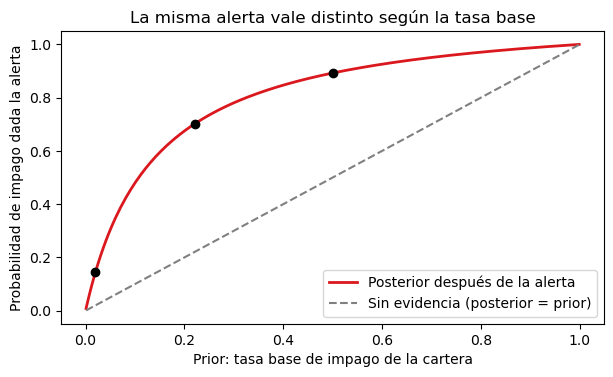

In [8]:
for cartera, prior in [('Premium', 0.02), ('General', 0.221), ('Refinanciados', 0.50)]:
    print(f'{cartera:14s} prior = {prior:.3f}  ->  posterior = {bayes(prior, 0.332, 0.040):.3f}')

# La curva completa: posterior en función del prior
priors = np.linspace(0.001, 0.999, 200)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(priors, bayes(priors, 0.332, 0.040), color='#DA181E', linewidth=2, label='Posterior después de la alerta')
ax.plot(priors, priors, color='gray', linestyle='--', label='Sin evidencia (posterior = prior)')
for prior in [0.02, 0.221, 0.50]:
    ax.plot(prior, bayes(prior, 0.332, 0.040), 'ko')
ax.set_xlabel('Prior: tasa base de impago de la cartera'); ax.set_ylabel('Probabilidad de impago dada la alerta')
ax.set_title('La misma alerta vale distinto según la tasa base'); ax.legend()
plt.show()

**Lectura:** posterior 0.145 en la cartera premium, 0.702 en la general y 0.892 en la de refinanciados. La curva roja siempre está por encima de la gris (la alerta siempre sube la probabilidad), pero **cuánto** sube depende del punto de partida.

Olvidar el prior y quedarse solo con "la alerta acierta el 33 % de los impagos y casi nunca suena con buenos clientes" se llama **falacia de la tasa base**. Aparece en diagnósticos médicos, en detección de fraude y en alertas tempranas de crisis: cuando el suceso es raro, **la mayoría de las alertas son falsas, aunque la alerta sea buena**. Lo retomaremos con las anomalías de la Unidad 4.

## 2.4 ¿Qué hace buena a una evidencia?

No importa cada verosimilitud por separado, sino su **cociente**:

$$\text{razón de verosimilitud} = \frac{P(A \mid I)}{P(A \mid \text{no } I)} = \frac{0.332}{0.040} \approx 8.3$$

La alerta es **8.3 veces más frecuente** entre los que impagan que entre los que pagan. Ese número mide la fuerza de la evidencia:

- razón = 1: el dato no dice nada (el posterior es igual al prior);
- razón mayor que 1: el dato apoya la hipótesis;
- razón menor que 1: el dato va en contra.

In [9]:
# Tres evidencias posibles sobre el mismo cliente, con el mismo prior de 22.1 %
evidencias = {
    'Alerta: 2+ meses de atraso en septiembre': X_train['atraso_sep'] >= 2,
    'Pagó en septiembre menos de 1 000':        X_train['pago_sep'] < 1000,
    'Es mujer':                                 X_train['sexo'] == 2,
    'Límite de crédito mayor que 300 000':      X_train['limite_credito'] > 300000,
}

filas = []
for nombre, dato in evidencias.items():
    si, no = dato[y_train == 1].mean(), dato[y_train == 0].mean()
    filas.append({'Evidencia': nombre, 'P(dato | impaga)': si, 'P(dato | paga)': no,
                  'Razón de verosimilitud': si / no, 'Posterior': bayes(p_impago, si, no)})
pd.DataFrame(filas).set_index('Evidencia').round(3)

,P(dato | impaga),P(dato | paga),Razón de verosimilitud,Posterior
Evidencia,,,,
Alerta: 2+ meses de atraso en septiembre,0.332,0.040,8.266,0.701
Pagó en septiembre menos de 1 000,0.358,0.218,1.644,0.318
Es mujer,0.572,0.615,0.930,0.209
Límite de crédito mayor que 300 000,0.084,0.170,0.494,0.123


**Lectura:**

- La **alerta de atraso** tiene razón 8.3 y lleva el 22 % al 70 %: evidencia fuerte.
- **Pagar poco en septiembre** es más frecuente entre los que impagan, pero también es frecuente entre los que pagan: razón 1.6, y el posterior sube solo a 0.32. Evidencia débil.
- **Ser mujer** tiene razón 0.9: casi no mueve nada (0.21).
- **Un cupo alto** tiene razón menor que 1: es evidencia **en contra** del impago; el posterior baja a 0.12.

Un dato puede ser muy frecuente entre los que impagan y aun así no servir: lo que importa es que sea **mucho más frecuente en un grupo que en el otro**.

# 3. Inferencia bayesiana: actualizar, medir la incertidumbre, decidir (2.3)

## 3.1 Actualización secuencial: el posterior de hoy es el prior de mañana

Un cliente tiene la alerta de septiembre: nuestra creencia pasó de 0.22 a 0.70. Ahora nos dicen que **también tuvo 2 o más meses de atraso en agosto** (suceso B). ¿Cómo actualizamos?

La receta: **usar 0.70 como nuevo prior** y aplicar Bayes otra vez con la nueva evidencia.

**A mano.** Del Train: P(B | I) = 0.374 y P(B | no I) = 0.084.

$$P(I \mid A, B) = \frac{0.374 \times 0.70}{0.374 \times 0.70 + 0.084 \times 0.30} = \frac{0.262}{0.262 + 0.025} \approx 0.91$$

Parece lógico: dos alertas, 91 % de impago. Comprobemos contando.

In [10]:
alerta_ago = (X_train['atraso_ago'] >= 2).rename('alerta_ago')

paso_1 = bayes(p_impago, alerta[y_train == 1].mean(), alerta[y_train == 0].mean())
paso_2 = bayes(paso_1, alerta_ago[y_train == 1].mean(), alerta_ago[y_train == 0].mean())

print(f'Prior                                   : {p_impago:.3f}')
print(f'Después de la alerta de septiembre      : {paso_1:.3f}')
print(f'Después de la alerta de agosto (cálculo): {paso_2:.3f}')
print(f'Conteo real, clientes con las dos alertas: {y_train[alerta & alerta_ago].mean():.3f}  ({(alerta & alerta_ago).sum()} clientes)')

Prior                                   : 0.221
Después de la alerta de septiembre      : 0.701
Después de la alerta de agosto (cálculo): 0.913
Conteo real, clientes con las dos alertas: 0.720  (1283 clientes)


**El cálculo dice 0.91 y la realidad dice 0.72.** ¿Qué falló? El teorema no: falló una **suposición escondida**.

Al usar P(B | I) = 0.374 supusimos que la alerta de agosto aporta información **nueva e independiente** de la de septiembre. No es así: quien tiene 2 meses de atraso en septiembre casi siempre ya tenía atraso en agosto. Las dos alertas cuentan, en buena parte, **la misma historia**.

Es como leer la misma noticia en dos periódicos que la copiaron de la misma agencia: no son dos confirmaciones, es una.

La actualización correcta usa la verosimilitud de B **entre los que ya tienen la alerta A**:

In [11]:
# Verosimilitud de la segunda alerta ENTRE los clientes que ya tienen la primera
b_si_impaga = alerta_ago[alerta & (y_train == 1)].mean()    # P(B | A, I)
b_si_paga = alerta_ago[alerta & (y_train == 0)].mean()      # P(B | A, no I)

print(f'P(B | A, impaga) = {b_si_impaga:.3f} · P(B | A, paga) = {b_si_paga:.3f} · razón = {b_si_impaga / b_si_paga:.2f}')
print(f'Actualización correcta: {bayes(paso_1, b_si_impaga, b_si_paga):.3f}')

P(B | A, impaga) = 0.699 · P(B | A, paga) = 0.638 · razón = 1.10
Actualización correcta: 0.720


**Lectura:** entre los clientes que ya tienen la alerta de septiembre, la de agosto aparece en el 70 % de los que impagan **y en el 64 % de los que pagan**. Su razón de verosimilitud es apenas 1.10: casi no dice nada nuevo. Con esas cifras, la actualización da **0.72**, igual que el conteo.

Dos lecciones:

1. **El posterior de hoy es el prior de mañana**: la actualización secuencial funciona.
2. **La evidencia repetida solo cuenta una vez.** Suponer que todas las evidencias son independientes es cómodo, pero produce probabilidades exageradas. Esa suposición tiene nombre, *ingenua* (naive), y es la base del clasificador **Naive Bayes** de la parte 4.

## 3.2 Cuando lo desconocido es una proporción

Hasta aquí la hipótesis era de sí o no ("este cliente impaga"). Ahora queremos estimar **un número**: la tasa de impago de un segmento del que tenemos pocos clientes.

El banco tiene un segmento pequeño: clientes con estado civil "otro" (código 3). ¿Su tasa de impago es mayor que el 22 % general?

En el enfoque bayesiano, lo desconocido (la tasa, que llamaremos θ) no tiene un único valor: tiene una **distribución de creencias**. Para una proporción se usa la distribución **Beta(a, b)**, que tiene una lectura muy simple:

> **Beta(a, b) = "es como haber visto a impagos y b pagos".**

Y actualizarla es **sumar**:

$$\text{prior Beta}(a, b) \;+\; \text{datos: } k \text{ impagos y } m \text{ pagos} \;\longrightarrow\; \text{posterior Beta}(a + k,\; b + m)$$

**El prior.** Antes de mirar el segmento, creemos que se parece a la cartera general (22 %), pero con poca seguridad: como si hubiéramos visto solo 10 clientes. Eso es Beta(2.2, 7.8): 2.2 impagos y 7.8 pagos "imaginarios".

**A mano.** Llegan los primeros 20 clientes del segmento: 9 impagan y 11 pagan.

- Posterior: Beta(2.2 + 9, 7.8 + 11) = **Beta(11.2, 18.8)**.
- Media del posterior: 11.2 / (11.2 + 18.8) = 11.2 / 30 = **0.373**.
- La frecuencia observada era 9 / 20 = 0.45. El posterior queda **entre** el prior (0.22) y los datos (0.45), más cerca de los datos porque hay 20 clientes reales contra 10 imaginarios.

In [13]:
a_prior, b_prior = 2.2, 7.8       # prior: "10 clientes imaginarios con 22 % de impago"

# A mano: 9 impagos y 11 pagos
a_post, b_post = a_prior + 9, b_prior + 11
print('Posterior: Beta(', a_post, ',', b_post, ') · media =', round(a_post / (a_post + b_post), 3))

# Intervalo creíble del 95 %: entre qué valores está la tasa con 95 % de probabilidad
print('Intervalo creíble 95 %:', stats.beta.ppf([0.025, 0.975], a_post, b_post).round(3))

Posterior: Beta( 11.2 , 18.8 ) · media = 0.373
Intervalo creíble 95 %: [0.212 0.55 ]


**Intervalo creíble:** con 20 clientes, la tasa del segmento está entre 0.21 y 0.55 con 95 % de probabilidad. Es un rango enorme: **20 clientes no alcanzan** para saber cuánto más riesgoso es el segmento.

La frase "la tasa está entre 0.21 y 0.55 con 95 % de probabilidad" es la lectura directa que casi todo el mundo quiere hacer, y **solo es correcta para un intervalo creíble bayesiano**. El intervalo de confianza clásico dice otra cosa (habla del procedimiento repetido muchas veces, no de este intervalo en particular).

## 3.3 La creencia se afina con cada lote

Ahora con los datos reales: tomamos los clientes del segmento en el orden en que aparecen en Train, **de 20 en 20**, y actualizamos después de cada lote.

Clientes del segmento: 188 · impagos: 52 · frecuencia: 0.277


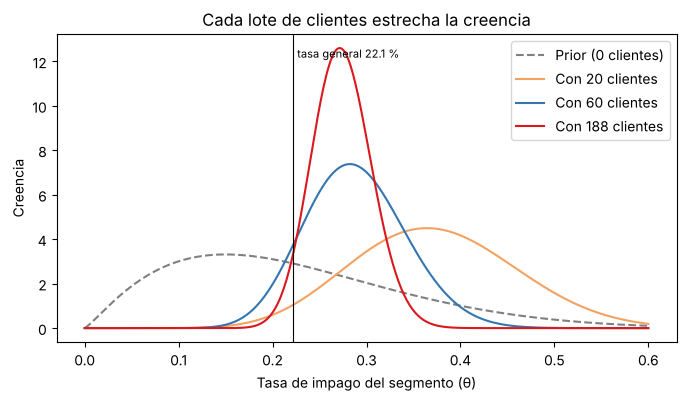

,Impagos,Media del posterior,IC 95 % bajo,IC 95 % alto,P(tasa > 22.1 %)
Clientes vistos,,,,,
20,9,0.373,0.212,0.550,0.967
60,18,0.289,0.189,0.399,0.898
188,52,0.274,0.214,0.338,0.956


In [14]:
segmento = y_train[X_train['estado_civil'] == 3]      # 1 = impagó, 0 = pagó
print('Clientes del segmento:', len(segmento), '· impagos:', int(segmento.sum()), '· frecuencia:', round(segmento.mean(), 3))

theta = np.linspace(0, 0.6, 400)                      # valores posibles de la tasa
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(theta, stats.beta.pdf(theta, a_prior, b_prior), color='gray', linestyle='--', label='Prior (0 clientes)')

a, b = a_prior, b_prior
filas = []
for vistos, color in zip([20, 60, len(segmento)], ['#F4A261', '#3476B1', '#DA181E']):
    lote = segmento.iloc[:vistos]
    a, b = a_prior + lote.sum(), b_prior + (len(lote) - lote.sum())     # sumar impagos y pagos
    bajo, alto = stats.beta.ppf([0.025, 0.975], a, b)
    filas.append({'Clientes vistos': vistos, 'Impagos': int(lote.sum()), 'Media del posterior': a / (a + b),
                  'IC 95 % bajo': bajo, 'IC 95 % alto': alto, 'P(tasa > 22.1 %)': 1 - stats.beta.cdf(p_impago, a, b)})
    ax.plot(theta, stats.beta.pdf(theta, a, b), color=color, label=f'Con {vistos} clientes')

ax.axvline(p_impago, color='black', linewidth=0.8); ax.text(p_impago + 0.005, ax.get_ylim()[1] * 0.92, 'tasa general 22.1 %', fontsize=8)
ax.set_xlabel('Tasa de impago del segmento (θ)'); ax.set_ylabel('Creencia'); ax.legend()
ax.set_title('Cada lote de clientes estrecha la creencia')
plt.show()
pd.DataFrame(filas).set_index('Clientes vistos').round(3)

**Cómo leer el gráfico:** cada curva es lo que creemos sobre la tasa del segmento. La gris es el prior: ancha, centrada cerca de 0.22. A medida que llegan clientes, la curva se hace **más alta y más estrecha**: sabemos más.

**Lectura de la tabla:** los primeros 20 clientes fueron una mala racha (9 impagos) y la estimación era 0.37; con 60 bajó a 0.29 y con los 188 quedó en 0.27, con un intervalo creíble de 0.21 a 0.34. Con pocos datos, la estimación se mueve mucho; por eso importa mirar el intervalo y no solo la media. La última columna responde directamente a la pregunta del banco: **la probabilidad de que el segmento sea más riesgoso que la cartera general es de alrededor de 0.96**. Bastante probable, pero no seguro: el 22.1 % todavía está dentro del intervalo.

Esa columna es la gran ventaja práctica del enfoque bayesiano: no devuelve "se rechaza o no se rechaza", devuelve **la probabilidad de lo que queremos saber**.

## 3.4 El prior pesa cuando hay pocos datos

¿Y si el prior fuera otro? Comparamos tres analistas con creencias iniciales distintas, con 20 clientes y con los 188.

In [15]:
analistas = {
    'Sin opinión: Beta(1, 1)': (1, 1),
    'Como la cartera general: Beta(2.2, 7.8)': (2.2, 7.8),
    'Convencido de 10 %: Beta(10, 90)': (10, 90),
}
filas = []
for nombre, (a0, b0) in analistas.items():
    fila = {'Prior': nombre, 'Media del prior': a0 / (a0 + b0)}
    for vistos in [20, len(segmento)]:
        lote = segmento.iloc[:vistos]
        a, b = a0 + lote.sum(), b0 + len(lote) - lote.sum()
        fila[f'Media con {vistos} clientes'] = a / (a + b)
    filas.append(fila)
pd.DataFrame(filas).set_index('Prior').round(3)

,Media del prior,Media con 20 clientes,Media con 188 clientes
Prior,,,
"Sin opinión: Beta(1, 1)",0.50,0.455,0.279
"Como la cartera general: Beta(2.2, 7.8)",0.22,0.373,0.274
"Convencido de 10 %: Beta(10, 90)",0.10,0.158,0.215


**Lectura:**

- Los dos primeros analistas (sin opinión y "como la cartera general") terminan casi en el mismo lugar con los 188 clientes: **los datos mandan**.
- El tercero estaba **muy** convencido de que la tasa era 10 % (su prior equivale a 100 clientes imaginarios). Con 20 clientes reales se mueve poco (de 0.10 a 0.16, mientras los otros ya están en 0.37 y 0.45); con 188 llega a 0.22, todavía por debajo de los otros.

**Regla:** con pocos datos, el prior importa mucho y hay que justificarlo. Con muchos datos, cualquier prior razonable lleva a la misma conclusión. Un prior muy seguro es una afirmación fuerte: exige mucha evidencia para corregirse.

## 3.5 De la probabilidad a la decisión

Una probabilidad no es una decisión. Para decidir hace falta saber **cuánto cuesta cada error**.

Supongamos que el banco puede **llamar al cliente** antes de octubre para ofrecerle un plan de pagos:

| | El cliente iba a pagar | El cliente iba a impagar |
|---|---|---|
| **Llamo** | costo 1 (llamada innecesaria: falso positivo) | costo 1 (llamada útil) |
| **No llamo** | costo 0 | **costo 5** (impago no gestionado: falso negativo) |

Sea p la probabilidad de impago del cliente.

- Costo esperado de **llamar**: 1 (siempre cuesta la llamada).
- Costo esperado de **no llamar**: 5 × p.

Conviene llamar cuando 5 × p > 1, es decir, cuando **p > 1/5 = 0.20**.

**A mano**, con tres clientes:

| Cliente | p (impago) | Costo de no llamar (5 × p) | Costo de llamar | Decisión |
|---|---:|---:|---:|---|
| Sin alertas | 0.14 | 0.70 | 1 | no llamar |
| Alerta solo en agosto | 0.41 | 2.05 | 1 | **llamar** |
| Alerta en septiembre | 0.70 | 3.50 | 1 | **llamar** |

El umbral no es 0.5: **lo ponen los costos, no el modelo**. Con una relación de costos de 5 a 1, basta un 20 % de probabilidad para actuar. Para que esta regla funcione, las probabilidades tienen que ser **creíbles** (si el modelo dice 0.41, deben impagar 41 de cada 100). Eso se llama **calibración** y lo medimos en la parte 5.

# 4. Modelos bayesianos (2.4)

Tres modelos, tres usos del mismo teorema:

| Modelo | Qué estima | Idea |
|---|---|---|
| **Naive Bayes** | la clase de un cliente | Bayes con muchas evidencias, suponiendo que son independientes |
| **Regresión bayesiana** | un número (con su incertidumbre) | los coeficientes de la regresión no son un valor fijo: tienen una distribución |
| **Red bayesiana** | cualquier variable a partir de las otras | un mapa de qué variable influye en cuál |

## 4.1 Naive Bayes

### La idea

Para clasificar a un cliente con muchas características, Naive Bayes hace exactamente el cálculo "equivocado" de la parte 3.1: **multiplica las verosimilitudes de cada característica como si fueran independientes**.

$$P(I \mid x_1, \ldots, x_n) \;\propto\; P(I) \times P(x_1 \mid I) \times P(x_2 \mid I) \times \cdots \times P(x_n \mid I)$$

Cada símbolo: $x_1, \ldots, x_n$ son las características del cliente; $P(x_j \mid I)$ es qué tan frecuente es ese valor entre los que impagan; el símbolo $\propto$ ("proporcional a") significa que al final se divide para que las probabilidades de impago y de pago sumen 1.

### A mano: un cliente con las dos alertas

| | Impaga | Paga |
|---|---:|---:|
| Prior | 0.221 | 0.779 |
| × P(alerta sep \| clase) | 0.332 | 0.040 |
| × P(alerta ago \| clase) | 0.374 | 0.084 |
| **Producto** | 0.221 × 0.332 × 0.374 = **0.0274** | 0.779 × 0.040 × 0.084 = **0.0026** |

Probabilidad de impago: 0.0274 / (0.0274 + 0.0026) ≈ **0.91**. Es el mismo 0.91 de la parte 3.1, cuando la realidad era 0.72.

Entonces, ¿por qué se usa? Porque **para clasificar no hace falta la probabilidad exacta, basta con ordenar bien**: un cliente con dos alertas es más riesgoso que uno con una, y Naive Bayes eso lo acierta. Además es rapidísimo, funciona con pocos datos y no tiene casi nada que ajustar.

### Con todas las variables

Con variables numéricas (facturas, pagos, edad), `GaussianNB` supone que cada una sigue una campana dentro de cada clase, y calcula su media y su desviación entre los que impagan y entre los que pagan.

In [12]:
resultados = {}

def evaluar(nombre, modelo):
    """Entrena con Train y mide en Validation: AUC (¿ordena bien?) y Brier (¿probabilidades creíbles?)."""
    modelo.fit(X_train, y_train)
    prob = modelo.predict_proba(X_val)[:, 1]
    resultados[nombre] = {
        'AUC': roc_auc_score(y_val, prob),
        'Brier': brier_score_loss(y_val, prob),
        'Probabilidad media': prob.mean(),
        'Clientes con p > 0.5': (prob > 0.5).mean(),
    }
    return modelo, prob

naive, prob_naive = evaluar('Naive Bayes', make_pipeline(StandardScaler(), GaussianNB()))
pd.DataFrame(resultados).T.round(3)

,AUC,Brier,Probabilidad media,Clientes con p > 0.5
Naive Bayes,0.734,0.216,0.406,0.302


**Dos métricas, dos preguntas:**

- **AUC = 0.73**: Naive Bayes **ordena** bien a los clientes, a la altura de un KNN bien ajustado de la Unidad 1 y por encima de la regla del atraso (0.68).
- **Brier**: es el error cuadrático medio entre la probabilidad predicha y lo que pasó (0 o 1). Cuanto más bajo, mejor. Un modelo que respondiera siempre "0.221" tendría un Brier de 0.172. Naive Bayes tiene **0.216: peor que no saber nada**.

¿Cómo puede ordenar bien y tener probabilidades malas? Mira las otras columnas: la probabilidad media que asigna es 0.41, cuando solo impaga el 22 %; y dice "más de 0.5" para el 30 % de los clientes. **Exagera**, por la misma razón del cálculo a mano: cuenta como evidencias independientes seis atrasos que en realidad cuentan la misma historia.

**Para recordar:** Naive Bayes es un buen **clasificador** y un mal **estimador de probabilidades**.

## 4.2 Regresión bayesiana

### La idea

En una regresión clásica, cada coeficiente es **un número**. En una regresión bayesiana, cada coeficiente tiene una **distribución**: un valor más probable y un margen de duda. Igual que con la tasa del segmento:

- **prior**: antes de ver datos, creemos que los coeficientes están cerca de cero (no hay efecto hasta que los datos lo demuestren);
- **datos**: mueven esa creencia;
- **posterior**: coeficientes con su incertidumbre.

Consecuencia práctica: la predicción también sale con su incertidumbre. **`BayesianRidge` devuelve dos cosas: el pronóstico y su desviación estándar.**

### El caso: la inflación del Módulo 5

En el Día 4 del Módulo 5 dijimos que el Random Forest "no da intervalos". La regresión bayesiana sí. Usamos la misma tabla de rezagos con tres columnas: el mes anterior, el mismo mes del año pasado y el promedio de los últimos 12 meses (el PM12).

In [13]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
inflacion = series['ipc_var_mensual'].loc['2005':].dropna()

# Tabla de aprendizaje supervisado (Módulo 5, Día 4): primero shift, después rolling
tabla_inflacion = pd.DataFrame({
    'objetivo': inflacion,
    'rezago_1': inflacion.shift(1),
    'rezago_12': inflacion.shift(12),
    'media_12': inflacion.shift(1).rolling(12).mean(),
}).dropna()

columnas = ['rezago_1', 'rezago_12', 'media_12']
entrena = tabla_inflacion.loc[:'2024-12']          # como en el Módulo 5: Train hasta 2024
prueba = tabla_inflacion.loc['2025-01':]           # Test: enero 2025 - agosto 2026

clasica = LinearRegression().fit(entrena[columnas], entrena['objetivo'])
bayesiana = BayesianRidge().fit(entrena[columnas], entrena['objetivo'])

# Coeficientes: valor y margen de duda (desviación estándar del posterior)
pd.DataFrame({
    'Regresión clásica': clasica.coef_,
    'Bayesiana: media': bayesiana.coef_,
    'Bayesiana: desviación': np.sqrt(np.diag(bayesiana.sigma_)),
}, index=columnas).round(3)

,Regresión clásica,Bayesiana: media,Bayesiana: desviación
rezago_1,0.339,0.329,0.064
rezago_12,0.230,0.226,0.067
media_12,0.209,0.188,0.128


**Lectura:** con 228 meses, los coeficientes bayesianos son casi iguales a los clásicos, apenas más cercanos a cero (el prior "tira" hacia cero). La columna nueva es la desviación: el coeficiente del mes anterior es 0.33 ± 0.06 (bien determinado), mientras que el del PM12 es 0.19 ± 0.13 (el modelo no está seguro de cuánto pesa).

### ¿Qué pasa con pocos datos?

Entrenamos con los últimos 24, 60 y 228 meses.

In [18]:
filas = []
for meses in [24, 60, 228]:
    reciente = entrena.iloc[-meses:]
    modelo = BayesianRidge().fit(reciente[columnas], reciente['objetivo'])
    _, desviacion = modelo.predict(prueba[columnas], return_std=True)
    filas.append({'Meses de entrenamiento': meses,
                  'coef. rezago_1': modelo.coef_[0], 'coef. rezago_12': modelo.coef_[1], 'coef. media_12': modelo.coef_[2],
                  'Incertidumbre media del pronóstico': desviacion.mean()})
pd.DataFrame(filas).set_index('Meses de entrenamiento').round(3)

,coef. rezago_1,coef. rezago_12,coef. media_12,Incertidumbre media del pronóstico
Meses de entrenamiento,,,,
24,0.001,0.002,-0.000,0.478
60,0.106,0.084,0.017,0.399
228,0.329,0.226,0.188,0.326


**Lectura:** con solo 24 meses, **los tres coeficientes son prácticamente cero**: el modelo dice "no tengo evidencia suficiente para afirmar que el pasado ayuda" y se queda con su prior. Con 60 meses empieza a creer en los rezagos; con 228 ya los estima con claridad. Y la incertidumbre del pronóstico baja de 0.48 a 0.33.

Una regresión clásica con 24 meses habría dado coeficientes grandes y poco fiables. La bayesiana **es prudente cuando sabe poco**: es el mismo comportamiento del analista de la parte 3.4.

### Pronóstico con intervalo en el Test

MAE regresión bayesiana : 0.317
MAE regresión clásica   : 0.321
MAE promedio móvil 12   : 0.286
Meses del Test dentro del intervalo del 95 %: 85%


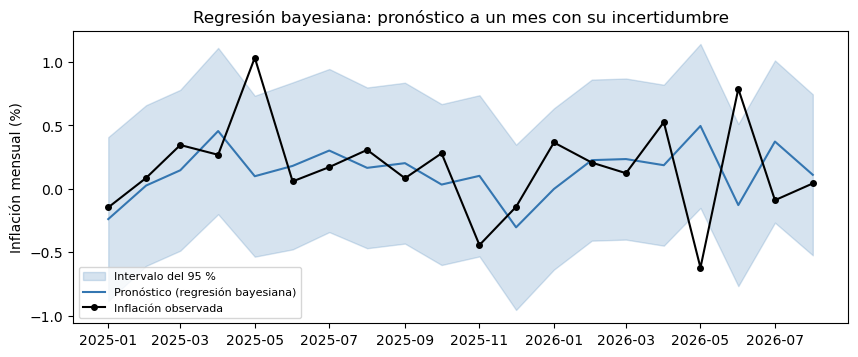

In [14]:
media, desviacion = bayesiana.predict(prueba[columnas], return_std=True)
bajo, alto = media - 1.96 * desviacion, media + 1.96 * desviacion

dentro = ((prueba['objetivo'] >= bajo) & (prueba['objetivo'] <= alto)).mean()
print(f'MAE regresión bayesiana : {mean_absolute_error(prueba["objetivo"], media):.3f}')
print(f'MAE regresión clásica   : {mean_absolute_error(prueba["objetivo"], clasica.predict(prueba[columnas])):.3f}')
print(f'MAE promedio móvil 12   : {mean_absolute_error(prueba["objetivo"], prueba["media_12"]):.3f}')
print(f'Meses del Test dentro del intervalo del 95 %: {dentro:.0%}')

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(prueba.index, bajo, alto, color='#3476B1', alpha=0.2, label='Intervalo del 95 %')
ax.plot(prueba.index, media, color='#3476B1', label='Pronóstico (regresión bayesiana)')
ax.plot(prueba.index, prueba['objetivo'], 'ko-', markersize=4, label='Inflación observada')
ax.set_ylabel('Inflación mensual (%)'); ax.legend(fontsize=8); ax.set_title('Regresión bayesiana: pronóstico a un mes con su incertidumbre')
plt.show()

**Lectura:**

- En precisión, **nada nuevo**: la regresión bayesiana (0.317) queda igual que la clásica y por detrás del PM12 (0.286), como todos los modelos del Módulo 5.
- Lo nuevo es la banda: un intervalo de más o menos 0.64 puntos alrededor de cada pronóstico, que contuvo al **85 %** de los meses del Test. Debería contener al 95 %: se queda algo corto, porque 2025 y 2026 tuvieron meses más extremos que el promedio histórico.

**Para recordar:** la regresión bayesiana no pronostica mejor; **dice cuánto confiar en el pronóstico**, y se vuelve prudente cuando tiene pocos datos.

## 4.3 Redes bayesianas

### La idea

Una red bayesiana es un **dibujo de flechas**: cada círculo es una variable y cada flecha dice "esta influye directamente en aquella". Cada variable guarda una tabla pequeña: su probabilidad **dado el valor de sus padres**.

Sirve para dos cosas: razonar **hacia adelante** (si pasa la causa, ¿qué tan probable es el efecto?) y **hacia atrás** (si veo el efecto, ¿qué tan probable es que haya pasado la causa?).

### Una red de tres nodos con datos del Ecuador

Con las series mensuales del Módulo 5 (2005 a 2026) definimos tres sucesos de sí o no para cada mes:

```
   Crudo cae        ──►     Riesgo país sube      ──►     Reservas bajan
 (WTI baja más              (sube más de 50              (las reservas internacionales
  de 5 % en el mes)          puntos básicos)              bajan en el mes)
```

La historia económica: cuando el petróleo cae, los mercados perciben más riesgo en el Ecuador; cuando el riesgo sube, las reservas tienden a bajar. Es una **simplificación** hecha para aprender el mecanismo, no un modelo de la economía.

In [15]:
periodo = series.loc['2005':'2026-08']

meses = pd.DataFrame({
    'crudo_cae': periodo['precio_wti_usd'].pct_change() < -0.05,
    'riesgo_sube': periodo['riesgo_pais_pb'].diff() > 50,
    'reservas_bajan': periodo['reservas_internacionales_musd'].pct_change() < 0,
}).iloc[1:]

print('Meses:', len(meses))
print('Frecuencia de cada suceso:', meses.mean().round(3).to_dict())

Meses: 259
Frecuencia de cada suceso: {'crudo_cae': 0.236, 'riesgo_sube': 0.208, 'reservas_bajan': 0.456}


Las tres tablas de la red se estiman contando, como en la parte 1:

- **P(crudo cae)**: no tiene padres; es su frecuencia.
- **P(riesgo sube | crudo)**: una fila por cada valor de su padre.
- **P(reservas bajan | riesgo)**: una fila por cada valor de su padre.

In [16]:
p_crudo = meses['crudo_cae'].mean()
tabla_riesgo = pd.crosstab(meses['crudo_cae'], meses['riesgo_sube'], normalize='index')
tabla_reservas = pd.crosstab(meses['riesgo_sube'], meses['reservas_bajan'], normalize='index')

print('P(crudo cae) =', round(p_crudo, 3), '\n')
print('P(riesgo sube | crudo cae):'); print(tabla_riesgo.round(3), '\n')
print('P(reservas bajan | riesgo sube):'); print(tabla_reservas.round(3))

P(crudo cae) = 0.236 

P(riesgo sube | crudo cae):
riesgo_sube  False  True 
crudo_cae                
False        0.869  0.131
True         0.541  0.459 

P(reservas bajan | riesgo sube):
reservas_bajan  False  True 
riesgo_sube                 
False           0.585  0.415
True            0.389  0.611


**Lectura de las tablas:**

- El crudo cae más de 5 % en el **24 %** de los meses.
- Si el crudo **no** cae, el riesgo país sube con probabilidad 0.13; si el crudo **cae**, con probabilidad **0.46**: tres veces y media más.
- Si el riesgo **no** sube, las reservas bajan con probabilidad 0.42; si el riesgo **sube**, con probabilidad **0.61**.

### Razonar hacia adelante (a mano)

**Pregunta:** este mes cayó el crudo. ¿Qué probabilidad hay de que bajen las reservas?

La red dice que el crudo solo afecta a las reservas **a través del riesgo**. Sumamos los dos caminos (probabilidad total):

$$P(\text{reservas bajan} \mid \text{crudo cae}) = \underbrace{0.459 \times 0.611}_{\text{el riesgo sube}} + \underbrace{0.541 \times 0.415}_{\text{el riesgo no sube}} = 0.280 + 0.225 = 0.505$$

### Razonar hacia atrás (a mano)

**Pregunta:** este mes subió el riesgo país. ¿Qué probabilidad hay de que haya caído el crudo? Es el teorema de Bayes:

$$P(\text{crudo cae} \mid \text{riesgo sube}) = \frac{0.459 \times 0.236}{0.459 \times 0.236 + 0.131 \times 0.764} = \frac{0.108}{0.108 + 0.100} \approx 0.52$$

Antes de saber nada, la probabilidad de una caída del crudo era 0.24. Al ver que el riesgo subió, pasa a 0.52.

In [22]:
# Hacia adelante: P(reservas bajan | crudo cae), sumando los dos caminos de la red
adelante = (tabla_riesgo.loc[True, True] * tabla_reservas.loc[True, True] +
            tabla_riesgo.loc[True, False] * tabla_reservas.loc[False, True])
print(f'P(reservas bajan | crudo cae)  red: {adelante:.3f} · conteo directo: {meses.loc[meses["crudo_cae"], "reservas_bajan"].mean():.3f}')

# Hacia atrás: P(crudo cae | riesgo sube), con la función bayes de la parte 2
atras = bayes(p_crudo, tabla_riesgo.loc[True, True], tabla_riesgo.loc[False, True])
print(f'P(crudo cae | riesgo sube)     red: {atras:.3f} · conteo directo: {meses.loc[meses["riesgo_sube"], "crudo_cae"].mean():.3f}')

P(reservas bajan | crudo cae)  red: 0.505 · conteo directo: 0.508
P(crudo cae | riesgo sube)     red: 0.519 · conteo directo: 0.519


**Lectura:** las respuestas de la red coinciden con el conteo directo en los datos (0.505 frente a 0.508 hacia adelante). Eso indica que la estructura de flechas que dibujamos es una descripción razonable: el crudo afecta a las reservas sobre todo a través del riesgo país.

**¿Para qué una red, si podemos contar?** Con 3 variables, contar basta. Con 20 variables de sí o no hay más de un millón de combinaciones y nunca habrá datos para contarlas todas. La red parte el problema en tablas pequeñas, una por variable.

**Conexión:** Naive Bayes **es** una red bayesiana, la más simple: una flecha desde la clase (impago) hacia cada característica, y ninguna flecha entre características. Por eso no ve que las alertas de agosto y septiembre están relacionadas.

**Cuidado:** las flechas las dibujamos nosotros, con una historia económica. Los datos dicen que las variables están asociadas, no que una cause la otra.

# 5. Caso económico: clasificación probabilística del impago (2.5)

**Qué vamos a hacer:** comparar el enfoque probabilístico (Naive Bayes) con dos modelos del Módulo 3 en lo que al banco le importa:

1. ¿**Ordena** bien a los clientes por riesgo? (AUC)
2. ¿Sus probabilidades son **creíbles**? (Brier y curva de calibración)
3. ¿Cuánto **cuesta** decidir con él? (la regla de costos de la parte 3.5)

In [23]:
logistica, prob_logistica = evaluar('Regresión logística (M3)', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
bosque, prob_bosque = evaluar('Random Forest (M3)', RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1))

# Referencia: responder siempre la tasa base
constante = np.full(len(y_val), y_train.mean())
resultados['Referencia: siempre 0.221'] = {'AUC': 0.5, 'Brier': brier_score_loss(y_val, constante),
                                           'Probabilidad media': constante.mean(), 'Clientes con p > 0.5': 0.0}
pd.DataFrame(resultados).T.round(3)

,AUC,Brier,Probabilidad media,Clientes con p > 0.5
Naive Bayes,0.734,0.216,0.406,0.302
Regresión logística (M3),0.724,0.145,0.219,0.076
Random Forest (M3),0.783,0.135,0.222,0.118
Referencia: siempre 0.221,0.500,0.172,0.221,0.000


**Lectura:**

| Modelo | ¿Ordena bien? (AUC) | ¿Probabilidades creíbles? (Brier) |
|---|---|---|
| Naive Bayes | 0.73, bien | **0.216: peor que responder siempre 0.221** |
| Regresión logística | 0.72, parecido | 0.145, bien |
| Random Forest | **0.78, el mejor** | **0.135, el mejor** |

Naive Bayes y la logística ordenan casi igual, pero la logística asigna una probabilidad media de 0.22, igual a la tasa real, y Naive Bayes de 0.41.

## 5.1 La curva de calibración

Agrupamos a los clientes según la probabilidad que les dio el modelo y, en cada grupo, miramos qué fracción impagó **de verdad**. En un modelo bien calibrado, los puntos caen sobre la diagonal: de los clientes con probabilidad 0.30, impaga el 30 %.

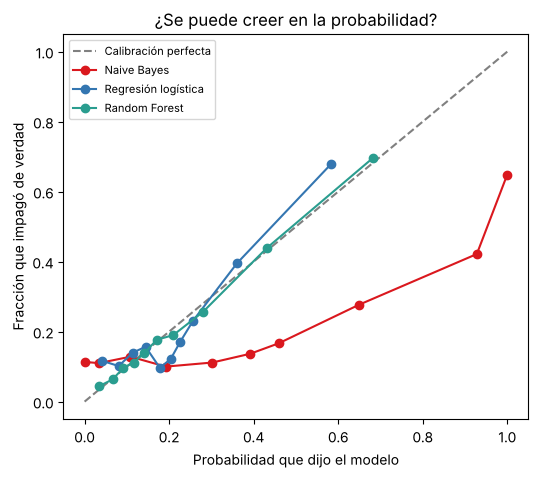

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Calibración perfecta')
for nombre, prob, color in [('Naive Bayes', prob_naive, '#DA181E'),
                            ('Regresión logística', prob_logistica, '#3476B1'),
                            ('Random Forest', prob_bosque, '#2A9D8F')]:
    observada, predicha = calibration_curve(y_val, prob, n_bins=10, strategy='quantile')
    ax.plot(predicha, observada, marker='o', color=color, label=nombre)
ax.set_xlabel('Probabilidad que dijo el modelo'); ax.set_ylabel('Fracción que impagó de verdad')
ax.set_title('¿Se puede creer en la probabilidad?'); ax.legend(fontsize=8)
plt.show()

**Cómo leerlo:** el Random Forest sigue la diagonal casi punto por punto y la logística se le acerca. Naive Bayes queda **muy por debajo**: en el grupo al que asigna 0.93 de probabilidad, en realidad impaga el 42 %; donde dice 0.65, impaga el 28 %. Es la exageración del cálculo a mano (0.91 frente a 0.72), ahora con seis atrasos y dieciocho variables más.

## 5.2 Decidir con costos

Aplicamos la regla de la parte 3.5: llamar cuesta 1; no llamar a quien impaga cuesta 5; se llama si p > 0.20. Comparamos el costo total en los 6 000 clientes de Validation con el umbral habitual (0.5) y con el umbral de los costos (0.20).

In [25]:
def costo_total(prob, umbral, costo_llamada=1, costo_impago=5):
    """Costo en Validation: se llama a quien supera el umbral; cada impago no llamado cuesta 5."""
    llamar = prob > umbral
    llamadas = llamar.sum() * costo_llamada
    impagos_no_gestionados = ((~llamar) & (y_val.values == 1)).sum() * costo_impago
    return llamadas + impagos_no_gestionados

filas = []
for nombre, prob in [('Naive Bayes', prob_naive), ('Regresión logística', prob_logistica), ('Random Forest', prob_bosque)]:
    filas.append({'Modelo': nombre,
                  'Costo con umbral 0.50': costo_total(prob, 0.50),
                  'Costo con umbral 0.20': costo_total(prob, 0.20),
                  'Clientes llamados (umbral 0.20)': int((prob > 0.20).sum()),
                  'Impagos detectados (umbral 0.20)': f'{((prob > 0.20) & (y_val.values == 1)).sum() / y_val.sum():.0%}'})

print('No llamar a nadie  :', int(y_val.sum()) * 5)
print('Llamar a todos     :', len(y_val))
print('Regla del atraso   :', costo_total((X_val['atraso_sep'] >= 2).astype(float).values, 0.5))
pd.DataFrame(filas).set_index('Modelo')

No llamar a nadie  : 6635
Llamar a todos     : 6000
Regla del atraso   : 5164


,Costo con umbral 0.50,Costo con umbral 0.20,Clientes llamados (umbral 0.20),Impagos detectados (umbral 0.20)
Modelo,,,,
Naive Bayes,4399,5084,3839,81%
Regresión logística,5444,4753,2778,70%
Random Forest,4956,4277,2222,69%


**Lectura.** Las referencias: no llamar a nadie cuesta 6 635; llamar a todos, 6 000; la regla del atraso, 5 164.

- **Random Forest** y **regresión logística**: al pasar del umbral 0.5 al 0.20, el costo **baja** (de 4 956 a 4 277 y de 5 444 a 4 753). Con 0.5 llaman a muy pocos clientes y dejan pasar impagos que cuestan 5. El Random Forest con umbral 0.20 es la mejor decisión de la tabla: llama a 2 222 clientes y alcanza al 69 % de los impagos.
- **Naive Bayes** hace lo contrario: con 0.5 cuesta 4 399 y con 0.20 **empeora** a 5 084. La regla de costos no falló: lo que pasa es que su "0.5" no es un 0.5 real. Como exagera las probabilidades, su umbral 0.5 equivale por casualidad a un umbral bajo, y con 0.20 termina llamando a 3 839 clientes, casi dos de cada tres. Con un modelo mal calibrado, el umbral que sale de los costos no sirve y habría que buscarlo a prueba y error.

**Lo que nos llevamos del caso:**

1. Un modelo se evalúa por **ordenar** (AUC), por **decir probabilidades creíbles** (Brier, calibración) y por **el costo de las decisiones** que produce. Son tres cosas distintas.
2. El **umbral lo ponen los costos**. Cambiar de 0.5 a 0.20 mejora la decisión más que cambiar de modelo.
3. Para decidir con probabilidades hace falta un modelo **calibrado**. Naive Bayes ordena bien pero exagera.

# Actividad 1: ¿Qué cambia cuando aparece evidencia? (20 puntos)

Se entrega en PDF, con los cálculos **a mano** y su explicación. Este notebook sirve para comprobar los resultados, no para reemplazarlos. La función `bayes(prior, p_dato_si_cierta, p_dato_si_falsa)` y `stats.beta` están disponibles en la celda siguiente.

In [26]:
# Espacio para comprobar los cálculos de la Actividad 1.
# Ejemplo: prior 0.10, la señal aparece en el 60 % de los casos positivos y en el 15 % de los negativos
print('Posterior:', round(bayes(0.10, 0.60, 0.15), 3))

# Ejemplo: prior Beta(2, 8); se observan 9 impagos y 21 pagos
print('Intervalo creíble 95 %:', stats.beta.ppf([0.025, 0.975], 2 + 9, 8 + 21).round(3))

Posterior: 0.308
Intervalo creíble 95 %: [0.15  0.421]


## Checklist de la unidad

- [ ] ¿Puedo explicar con 1 000 clientes por qué P(impago | alerta) no es P(alerta | impago)?
- [ ] ¿Sé nombrar el prior, la verosimilitud, la evidencia y el posterior en un problema nuevo?
- [ ] ¿Pregunté por la **tasa base** antes de interpretar una alerta?
- [ ] ¿Revisé si dos evidencias cuentan la misma historia antes de multiplicarlas?
- [ ] ¿Puedo leer un intervalo creíble y explicar por qué se estrecha con más datos?
- [ ] ¿Sé por qué Naive Bayes ordena bien y exagera las probabilidades?
- [ ] ¿Sé qué añade la regresión bayesiana a una regresión clásica?
- [ ] ¿Elegí el umbral con los costos de cada error y no por costumbre?

**Puente a la Unidad 3:** la regresión logística que usamos hoy como comparación toma las variables del cliente, las multiplica por unos pesos, las suma y pasa el resultado por una curva en forma de S para obtener una probabilidad. Eso es, exactamente, **una neurona artificial**.